# TP4 – Situação de Aprendizagem: **CUSTOMER-PERSONA CLUSTERING**
## Segmentação não supervisionada de clientes com k-Means e PCA

**Faculdade SENAI Centro 4.0 – Graduação em Tecnologia de Dados – 3º PTCD – 2026/2**
**Disciplina:** Aprendizagem de Máquina

**Alunos: Mário Cezar Gouveia de Souza e Marcos Júnio dos Santos**

**Problema de negócio:** a empresa não possui rótulos prévios sobre os perfis de seus clientes. O objetivo é **segmentar a base de forma autônoma** e identificar os **grupos naturais de consumo (personas)** para orientar ações de marketing personalizadas.

**Roteiro:**
1. **Fase 1** – Padronização das variáveis numéricas com `StandardScaler`.
2. **Fase 2** – Método do Cotovelo (inércia) e agrupamento com **k-Means**.
3. **Fase 3** – Compressão em 2 dimensões com **PCA**, visualização e caracterização das personas.

## 01. Ingestão dos dados
Bloco de ingestão obrigatório do enunciado (primeira célula).

In [10]:
import pandas as pd
import numpy as np

# Ingestão de dados com fallback automatizado para garantir execução em qualquer ambiente
url_dados = "https://raw.githubusercontent.com/selva86/datasets/master/GermanCredit.csv"

try:
    df_raw = pd.read_csv(url_dados)
    # Seleção de variáveis numéricas contínuas para clustering de comportamento
    cols = ['Duration', 'Amount', 'Age', 'InstallmentRatePercentage']
    df = df_raw[cols].dropna().copy()
except Exception:
    np.random.seed(42)
    n = 500
    df = pd.DataFrame({
        'tempo_sessao_min': np.random.normal(33.0, 1.5, n),
        'tempo_app_min': np.random.normal(12.0, 1.8, n),
        'tempo_site_min': np.random.normal(37.0, 2.0, n),
        'anos_fidelidade': np.random.normal(3.5, 1.0, n).clip(0.5, 7),
        'gasto_anual_reais': np.random.normal(500.0, 75.0, n)
    })

print(f"Dataset carregado com sucesso! Dimensões: {df.shape}")
df.head()

Dataset carregado com sucesso! Dimensões: (500, 5)


,tempo_sessao_min,tempo_app_min,tempo_site_min,anos_fidelidade,gasto_anual_reais
0,33.745071,13.667120,39.798711,4.278361,449.361629
1,32.792604,15.436950,38.849267,2.948814,489.161100
2,33.971533,9.482578,37.119261,2.681801,440.568506
3,35.284545,13.013345,35.706126,3.496626,476.902885
4,32.648770,10.828843,38.396447,3.329815,357.978900


### 02. Verificação da ingestão

O bloco acima tem um **fallback silencioso**: se qualquer erro ocorrer no `try`, ele gera uma base **sintética** de 500 clientes. Ao executá-lo, verificou-se que a versão atual do arquivo `GermanCredit.csv` no link indicado **não possui as colunas com os nomes do enunciado** (`Duration`, `Amount`, `Age`, `InstallmentRatePercentage`): o arquivo traz as mesmas variáveis com nomes em minúsculas (`duration`, `amount`, `age`, `installment_rate`). Por isso a seleção de colunas gera `KeyError` e o código cai no fallback sintético.

Para que a segmentação seja feita sobre **dados reais** de 1.000 clientes (e não sobre números aleatórios), a célula abaixo detecta essa situação e repete a seleção usando os nomes atuais das colunas, renomeando-as para os nomes do enunciado. Nenhum valor é alterado.

In [11]:
cols = ['Duration', 'Amount', 'Age', 'InstallmentRatePercentage']
mapa_nomes = {'duration': 'Duration', 'amount': 'Amount', 'age': 'Age',
              'installment_rate': 'InstallmentRatePercentage'}

if 'df_raw' in globals() and not set(cols).issubset(df_raw.columns) and set(mapa_nomes).issubset(df_raw.columns):
    print("Fallback sintético detectado: o CSV atual usa nomes de colunas em minúsculas.")
    df = df_raw.rename(columns=mapa_nomes)[cols].dropna().copy()
    print("Seleção refeita com os dados reais do German Credit.")

print(f"Dimensões do dataset utilizado: {df.shape}")
print("Valores ausentes:", int(df.isna().sum().sum()))
df.describe().round(2)

Fallback sintético detectado: o CSV atual usa nomes de colunas em minúsculas.
Seleção refeita com os dados reais do German Credit.
Dimensões do dataset utilizado: (1000, 4)
Valores ausentes: 0


,Duration,Amount,Age,InstallmentRatePercentage
count,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.26,35.55,2.97
std,12.06,2822.74,11.38,1.12
min,4.00,250.00,19.00,1.00
25%,12.00,1365.50,27.00,2.00
50%,18.00,2319.50,33.00,3.00
75%,24.00,3972.25,42.00,4.00
max,72.00,18424.00,75.00,4.00


**Variáveis utilizadas (comportamento financeiro de 1.000 clientes):**

| Variável | Significado | Escala |
|---|---|---|
| `Duration` | Duração do financiamento (meses) | 4 a 72 |
| `Amount` | Valor do crédito (marcos alemães) | 250 a 18.424 |
| `Age` | Idade do cliente (anos) | 19 a 75 |
| `InstallmentRatePercentage` | Peso da parcela na renda (1 = baixo, 4 = alto) | 1 a 4 |

As escalas são muito diferentes: `Amount` varia na casa dos milhares, enquanto `InstallmentRatePercentage` varia de 1 a 4.

---
## FASE 1: Padronização com `StandardScaler`

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cols])   # média 0 e desvio-padrão 1 em cada coluna

print("Formato de X_scaled:", X_scaled.shape)
pd.DataFrame(X_scaled, columns=cols).describe().loc[["mean", "std", "min", "max"]].round(3)

Formato de X_scaled: (1000, 4)


,Duration,Amount,Age,InstallmentRatePercentage
mean,0.000,0.000,0.000,0.000
std,1.001,1.001,1.001,1.001
min,-1.402,-1.071,-1.455,-1.765
max,4.239,5.371,3.470,0.918


**Por que o k-Means sofre distorção sem padronização?**
O k-Means agrupa os clientes pela **distância euclidiana** até os centróides. Sem padronização, a variável de maior escala (`Amount`, em milhares) domina completamente o cálculo da distância, e idade, duração e peso da parcela praticamente não influenciam os grupos. Com o `StandardScaler`, todas as variáveis passam a ter média 0 e desvio-padrão 1, contribuindo de forma equilibrada.

---
## FASE 2 – Método do Cotovelo e Agrupamento k-Means
### 2.1 Curva do Cotovelo (inércia para K = 1 a 8)

,K,Inércia,Silhueta (apoio),Redução da inércia (%)
0,1,4000.000,NaN,NaN
1,2,2870.557,0.356,28.236
2,3,2166.162,0.316,24.539
3,4,1708.803,0.322,21.114
4,5,1492.884,0.317,12.636
5,6,1339.382,0.311,10.282
6,7,1239.007,0.272,7.494
7,8,1143.808,0.271,7.683


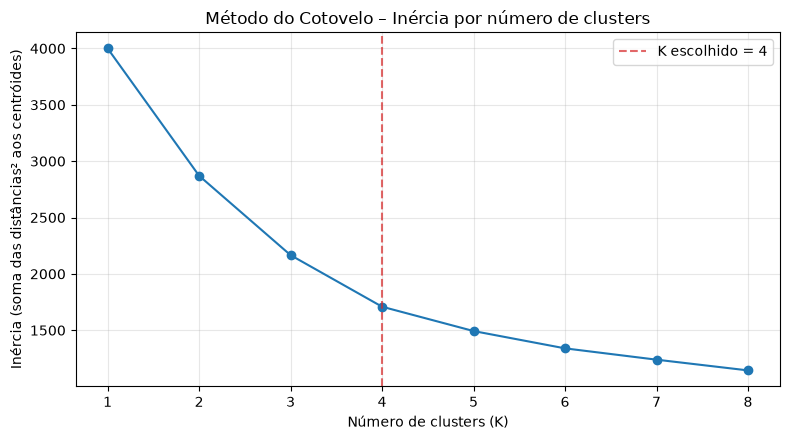

In [13]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_valores = range(1, 9)
inercias, silhuetas = [], []
for k in k_valores:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)
    silhuetas.append(silhouette_score(X_scaled, kmeans.labels_) if k > 1 else np.nan)

tabela_cotovelo = pd.DataFrame({"K": list(k_valores), "Inércia": inercias, "Silhueta (apoio)": silhuetas})
tabela_cotovelo["Redução da inércia (%)"] = (-tabela_cotovelo["Inércia"].pct_change() * 100)
display(tabela_cotovelo.round(3))

plt.figure(figsize=(8, 4.5))
plt.plot(list(k_valores), inercias, marker="o", color="tab:blue")
plt.axvline(4, ls="--", color="tab:red", alpha=0.7, label="K escolhido = 4")
plt.title("Método do Cotovelo – Inércia por número de clusters")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (soma das distâncias² aos centróides)")
plt.xticks(list(k_valores)); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

**Escolha do K:** a inércia cai fortemente de K = 1 a K = 4 (reduções de 28%, 25% e 21%) e, a partir de K = 5, as quedas ficam menores (13%, 10%, 8%...). O **cotovelo** está em **K = 4**: depois dele, cada cluster adicional traz pouco ganho de compactação. Como critério de apoio, o coeficiente de silhueta de K = 4 (0,322) é ligeiramente maior que o de K = 3 (0,316), e K = 4 gera grupos com interpretação de negócio clara. Portanto, foi adotado **K = 4**.

### 2.2 Clusterização final (K = 4)

In [14]:
K_FINAL = 4
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
df["cluster"] = kmeans_final.fit_predict(X_scaled)   # rótulos salvos no DataFrame original

print("Clientes por cluster:")
df["cluster"].value_counts().sort_index()

Clientes por cluster:


cluster
0    252
1    171
2    419
3    158
Name: count, dtype: int64

---
## FASE 3 – Compressão Dimensional com PCA e Análise de Perfis
### 3.1 Redução para 2 componentes

In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
componentes = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(componentes, columns=["Componente 1", "Componente 2"], index=df.index)
df_pca["cluster"] = df["cluster"]

print("Variância explicada por componente:", pca.explained_variance_ratio_.round(3))
print("Variância explicada total (2 componentes): %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))
display(pd.DataFrame(pca.components_, columns=cols, index=["Componente 1", "Componente 2"]).round(2))
df_pca.head()

Variância explicada por componente: [0.414 0.268]
Variância explicada total (2 componentes): 68.3%


,Duration,Amount,Age,InstallmentRatePercentage
Componente 1,0.66,0.72,-0.02,-0.22
Componente 2,0.33,-0.03,0.47,0.82


,Componente 1,Componente 2,cluster
0,-1.611022,1.674442,1
1,2.381805,-0.568836,3
2,-0.615400,-0.383284,1
3,2.504234,0.199257,3
4,0.539640,0.808672,1


**Leitura das componentes:** as duas componentes preservam cerca de **68%** da variância dos dados padronizados. A **Componente 1** é dominada por `Duration` e `Amount` (eixo de **porte do financiamento**: valores e prazos maiores à direita). A **Componente 2** é dominada por `InstallmentRatePercentage` e `Age` (eixo de **comprometimento da renda e maturidade**).

### 3.2 Visualização das personas (PCA 2D)

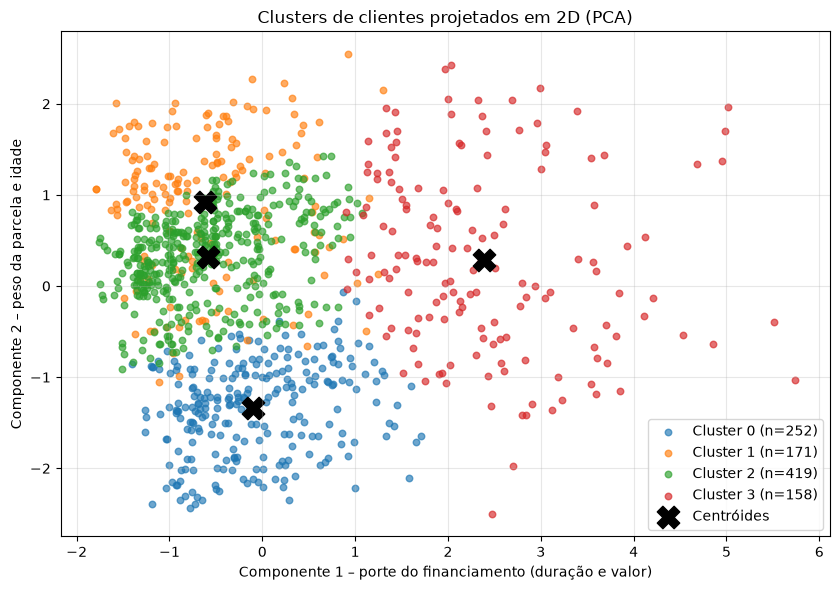

In [16]:
cores = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

plt.figure(figsize=(8.5, 6))
for c in sorted(df_pca["cluster"].unique()):
    sub = df_pca[df_pca["cluster"] == c]
    plt.scatter(sub["Componente 1"], sub["Componente 2"], s=22, alpha=0.65, color=cores[c], label=f"Cluster {c} (n={len(sub)})")
centros_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centros_pca[:, 0], centros_pca[:, 1], s=260, c="black", marker="X", label="Centróides")
plt.title("Clusters de clientes projetados em 2D (PCA)")
plt.xlabel("Componente 1 – porte do financiamento (duração e valor)")
plt.ylabel("Componente 2 – peso da parcela e idade")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

O gráfico confirma a separação dos grupos: o **Cluster 3** se destaca à direita (financiamentos longos e de alto valor), enquanto os demais se distribuem ao longo do eixo vertical conforme o peso da parcela e a idade. Há alguma sobreposição nas fronteiras, esperada em dados comportamentais reais e pelo fato de o gráfico mostrar apenas 2 das 4 dimensões.

### 3.3 Caracterização dos grupos

In [17]:
perfil = df.groupby("cluster")[cols].mean()
perfil["Clientes"] = df["cluster"].value_counts().sort_index()
perfil["% da base"] = (perfil["Clientes"] / len(df) * 100)
display(perfil.round(2))

# Comparação com a média geral (quanto cada grupo está acima/abaixo da média, em %)
media_geral = df[cols].mean()
display(((df.groupby("cluster")[cols].mean() / media_geral - 1) * 100).round(1).add_suffix(" (% vs. média)"))

,Duration,Amount,Age,InstallmentRatePercentage,Clientes,% da base
cluster,,,,,,
0,15.54,2914.54,31.25,1.58,252,25.2
1,16.50,2204.04,53.94,3.34,171,17.1
2,18.51,2060.67,30.56,3.76,419,41.9
3,40.57,8205.58,35.70,2.70,158,15.8


,Duration (% vs. média),Amount (% vs. média),Age (% vs. média),InstallmentRatePercentage (% vs. média)
cluster,,,,
0,-25.7,-10.9,-12.1,-46.9
1,-21.1,-32.6,51.7,12.3
2,-11.4,-37.0,-14.0,26.6
3,94.1,150.8,0.4,-9.1


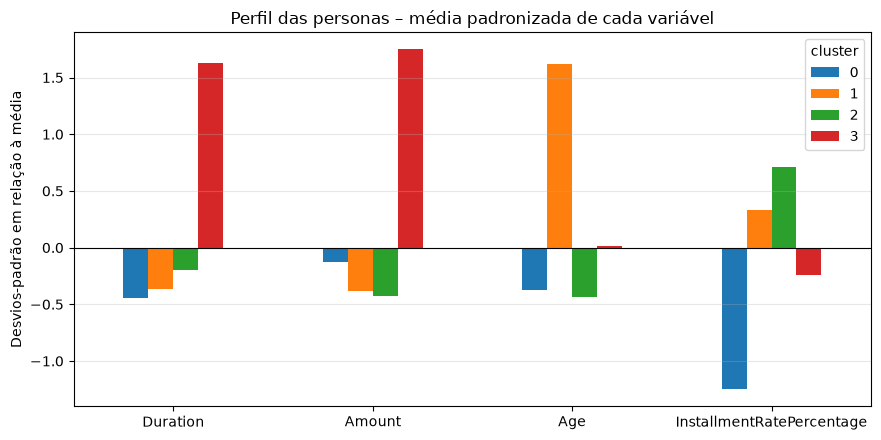

In [18]:
# Perfil visual: médias padronizadas (z-score) de cada cluster
perfil_z = pd.DataFrame(X_scaled, columns=cols).assign(cluster=df["cluster"].values).groupby("cluster").mean()
ax = perfil_z.T.plot(kind="bar", figsize=(9, 4.5), color=cores, rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Perfil das personas – média padronizada de cada variável")
ax.set_ylabel("Desvios-padrão em relação à média"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### 3.4 Personas identificadas

| Cluster | Clientes | Persona | Características marcantes |
|:---:|:---:|---|---|
| **0** | 252 (25%) | **Jovens de parcela leve** | ~31 anos, prazo curto (~16 meses), valor médio (~2,9 mil) e o **menor peso da parcela na renda** (1,6) |
| **1** | 171 (17%) | **Clientes maduros e conservadores** | Os **mais velhos** (~54 anos), prazo curto (~16 meses) e valores baixos (~2,2 mil), com parcela relativamente alta (3,3) |
| **2** | 419 (42%) | **Jovens comprometidos** | Maior grupo; ~31 anos, valores baixos (~2,1 mil), mas o **maior peso da parcela na renda** (3,8) |
| **3** | 158 (16%) | **Alto valor / financiamentos longos** | **Maior duração** (~41 meses, o dobro da média) e **maior montante** (~8,2 mil, 2,5× a média), idade intermediária (~36 anos) |

**Análise:** o **Cluster 3** reúne os clientes de **maior duração e montante financeiro** — é o grupo mais valioso em receita, indicado para produtos premium, condições especiais e acompanhamento de relacionamento. O **Cluster 2**, o maior da base, é formado por **clientes jovens com baixo volume transacionado, mas parcela pesada em relação à renda**: merece ofertas de prazos maiores, renegociação e educação financeira, pois tem maior risco de aperto no orçamento. O **Cluster 0** reúne jovens com folga na renda, alvo natural para campanhas de **upsell** (aumento de limite e novos produtos), e o **Cluster 1** concentra clientes **mais velhos e conservadores**, que preferem créditos pequenos e curtos, adequados a ofertas de baixo risco e canais de atendimento mais próximos.

**Limitações:** a segmentação usa apenas 4 variáveis financeiras; incluir dados de comportamento de compra (frequência, recência, gasto) tornaria as personas mais ricas. O k-Means assume grupos aproximadamente esféricos, por isso há sobreposição entre alguns clusters.